# AlertaBairro — Análise de Ocorrências Urbanas

**GS CitizenTech 2026.2 · Engenharia de Software · FIAP**

**Integrantes:** `[Nicolas Forcione de Oliveira e Souza – RM566998

Alexandre Constantino Furtado Junior – RM567188    
Leonardo Batista de Souza – RM568558  
Matheus Freitas dos Santos– RM567337]`

## Contexto

O **AlertaBairro** é uma plataforma comunitária para registrar e acompanhar ocorrências urbanas (alagamentos, bueiros entupidos, deslizamentos) em bairros com histórico de risco. Este notebook analisa uma base de ocorrências para entender onde e quando os problemas mais acontecem, e como se relacionam com o volume de chuva.

> **Fonte dos dados:** base simulada pela equipe para fins didáticos do projeto, com padrões inspirados em boletins públicos de ocorrências e dados pluviométricos de centros de monitoramento municipais (ex.: CGE-SP). Não contém dados pessoais reais. Os nomes de bairro são fictícios — substituam pela área real escolhida pela equipe.

## Perguntas de negócio

1. Quais bairros concentram mais ocorrências?
2. Qual o tipo de ocorrência mais recorrente?
3. Existe relação entre o volume de chuva e a gravidade da ocorrência?
4. Qual o tempo médio de resolução das ocorrências, e ele muda conforme a gravidade?


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("dados_ocorrencias_alertabairro.csv", parse_dates=["data_registro"])
print(df.shape)
print(df.head().to_string())


(320, 11)
   id_ocorrencia data_registro            bairro    tipo_ocorrencia                                                    descricao gravidade  chuva_mm_24h  latitude  longitude        status  dias_para_resolucao
0              1    2026-05-01       Cidade Alta    Bueiro entupido         Bueiro entupido reportado por morador em Cidade Alta      Alta          55.9 -23.47369  -46.59520     Resolvida                 10.0
1              2    2026-05-01  Jardim Esperança    Bueiro entupido    Bueiro entupido reportado por morador em Jardim Esperança     Média          32.4 -23.52534  -46.63070     Resolvida                  4.0
2              3    2026-05-01  Jardim Esperança         Alagamento         Alagamento reportado por morador em Jardim Esperança     Baixa           0.0 -23.50539  -46.61717  Em andamento                  NaN
3              4    2026-05-01  Jardim Esperança  Rua intransitável  Rua intransitável reportado por morador em Jardim Esperança     Média          44.8 -

## Preparação dos dados

In [15]:
print("Linhas e colunas:", df.shape)
print("\nTipos de dado:")
print(df.dtypes)
print("\nValores nulos por coluna:")
print(df.isna().sum())

# gravidade como categoria ordenada (Baixa < Média < Alta)
ordem_gravidade = ["Baixa", "Média", "Alta"]
df["gravidade"] = pd.Categorical(df["gravidade"], categories=ordem_gravidade, ordered=True)

# coluna auxiliar de mês, para a série temporal
df["mes"] = df["data_registro"].dt.to_period("M").astype(str)


Linhas e colunas: (320, 11)

Tipos de dado:
id_ocorrencia                   int64
data_registro          datetime64[ns]
bairro                         object
tipo_ocorrencia                object
descricao                      object
gravidade                      object
chuva_mm_24h                  float64
latitude                      float64
longitude                     float64
status                         object
dias_para_resolucao           float64
dtype: object

Valores nulos por coluna:
id_ocorrencia            0
data_registro            0
bairro                   0
tipo_ocorrencia          0
descricao                0
gravidade                0
chuva_mm_24h             0
latitude                 0
longitude                0
status                   0
dias_para_resolucao    127
dtype: int64


## Análise descritiva

### 1. Ocorrências por bairro

bairro
Jardim Esperança    118
Vila Rio Verde       76
Parque das Águas     53
Cidade Alta          43
Recanto do Vale      30
Name: count, dtype: int64


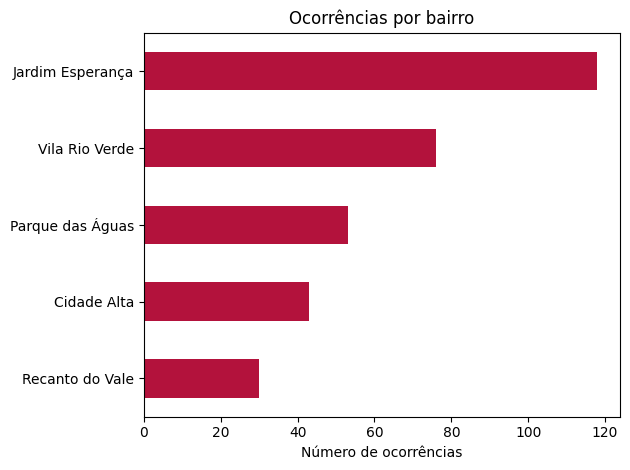

In [16]:
contagem_bairro = df["bairro"].value_counts()
print(contagem_bairro)

contagem_bairro.sort_values().plot(kind="barh", color="#b3123c")
plt.title("Ocorrências por bairro")
plt.xlabel("Número de ocorrências")
plt.ylabel("")
plt.tight_layout()
plt.show()


### 2. Tipo de ocorrência mais recorrente

tipo_ocorrencia
Alagamento               127
Bueiro entupido           97
Rua intransitável         62
Deslizamento de terra     34
Name: count, dtype: int64


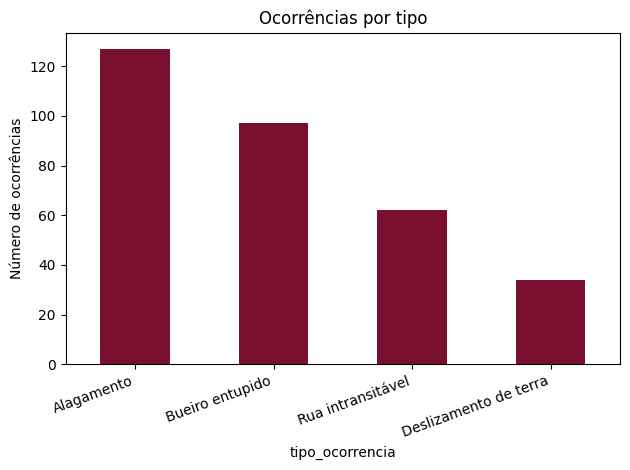

In [17]:
contagem_tipo = df["tipo_ocorrencia"].value_counts()
print(contagem_tipo)

contagem_tipo.plot(kind="bar", color="#7a1030")
plt.title("Ocorrências por tipo")
plt.ylabel("Número de ocorrências")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### 3. Chuva nas 24h anteriores x gravidade da ocorrência

           count  mean   std  min   25%   50%   75%   max
gravidade                                                
Baixa      100.0  13.8  13.1  0.0   0.0  12.7  20.1  43.9
Média      123.0  30.4  16.3  0.0  21.0  31.2  39.6  69.1
Alta        97.0  41.0  16.2  0.0  29.6  39.3  52.6  73.3


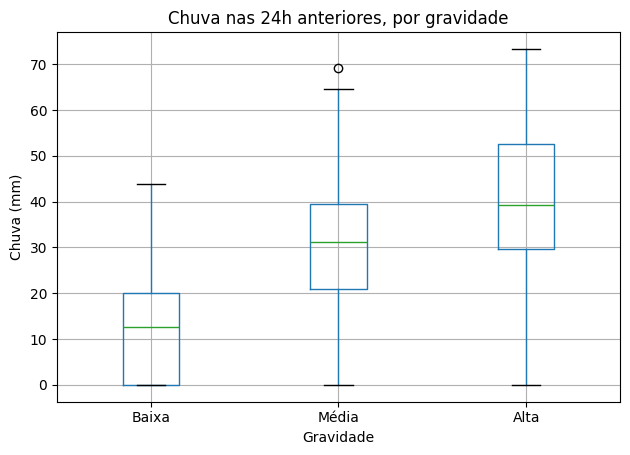

In [18]:
print(df.groupby("gravidade", observed=True)["chuva_mm_24h"].describe().round(1))

df.boxplot(column="chuva_mm_24h", by="gravidade")
plt.title("Chuva nas 24h anteriores, por gravidade")
plt.suptitle("")
plt.xlabel("Gravidade")
plt.ylabel("Chuva (mm)")
plt.tight_layout()
plt.show()


### 4. Ocorrências por mês

mes
2026-05    53
2026-06    57
2026-07    62
2026-08    57
2026-09    48
2026-10    43
dtype: int64


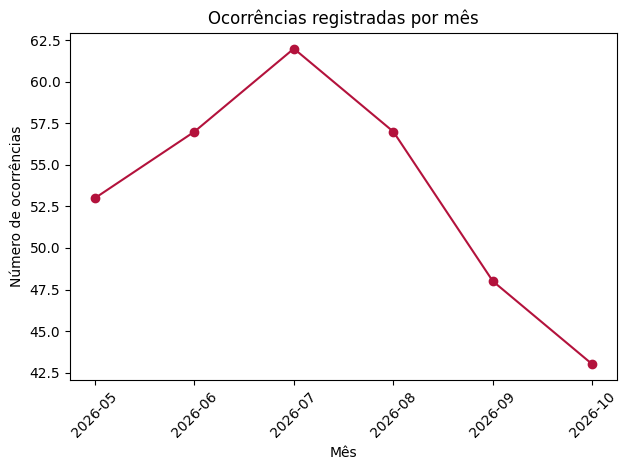

In [19]:
ocorrencias_mes = df.groupby("mes").size()
print(ocorrencias_mes)

ocorrencias_mes.plot(kind="line", marker="o", color="#b3123c")
plt.title("Ocorrências registradas por mês")
plt.ylabel("Número de ocorrências")
plt.xlabel("Mês")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 5. Status e tempo médio de resolução

In [20]:
print(df["status"].value_counts())

resolvidas = df[df["status"] == "Resolvida"]
tempo_medio = resolvidas.groupby("gravidade", observed=True)["dias_para_resolucao"].mean().round(1)
print("\nTempo médio de resolução (dias), por gravidade:")
print(tempo_medio)


status
Resolvida       193
Em andamento     78
Aberta           49
Name: count, dtype: int64

Tempo médio de resolução (dias), por gravidade:
gravidade
Baixa    2.9
Média    5.6
Alta     7.9
Name: dias_para_resolucao, dtype: float64


## Conclusões

1. **Concentração por bairro** — Jardim Esperança concentra o maior número de ocorrências da base (36.9% do total), o que é coerente com simular uma região próxima a curso d'água. Esse tipo de recorte é o que o módulo de monitoramento do AlertaBairro precisa destacar no mapa.
2. **Tipo mais recorrente** — "Alagamento" é o tipo de ocorrência mais registrado (39.7% do total), reforçando que o cadastro do morador deve priorizar esse fluxo (campos e categorias) na interface.
3. **Chuva x gravidade** — ocorrências classificadas como Alta gravidade aconteceram, em média, com 41.0 mm de chuva nas 24h anteriores, contra 13.8 mm nas de Baixa gravidade. Isso confirma a hipótese do briefing: volume de chuva é um bom sinal para o módulo de inteligência priorizar alertas.
4. **Tempo de resolução** — o tempo médio de resolução cresce com a gravidade ({'Baixa': 2.9, 'Média': 5.6, 'Alta': 7.9} dias), o que sugere que o módulo administrativo deveria ter um indicador de SLA por gravidade, não um prazo único para todas as ocorrências.

**Próximos passos:** repetir esta análise com dados reais (ou mais próximos da realidade) assim que a equipe definir o bairro de estudo e conseguir dados pluviométricos públicos da região (ex. CGE-SP, INMET).